In [ ]:
# INTERACTIVIDAD

In [ ]:
# CELDA INTERACTIVA PARA COLAB: Manipula dimensiones latentes con sliders
# Pega todo esto en una sola celda en Google Colab y ejecútalo.

# (1) Instalaciones necesarias en Colab (descomenta si hace falta)
# !pip install -q ipywidgets
# from google.colab import output
# output.enable_custom_widget_manager()

# (2) Imports
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, clear_output

# (3) Device y semilla
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(42)
np.random.seed(42)
print("Device:", device)

# (4) Dataset (MNIST) y DataLoader (rápido)
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])
train_ds = datasets.MNIST(root="data", train=True, download=True, transform=transform)
test_ds  = datasets.MNIST(root="data", train=False, download=True, transform=transform)

# Usaremos subset para acelerar entrenamiento en demo
TRAIN_SUBSET_SIZE = 10000
train_loader = DataLoader(Subset(train_ds, list(range(TRAIN_SUBSET_SIZE))), batch_size=256, shuffle=True)
test_loader  = DataLoader(test_ds, batch_size=256, shuffle=False)

# (5) Autoencoder (no-lineal pequeño) - definimos en la celda para facilidad
class NonlinearAutoencoderSmall(nn.Module):
    def __init__(self, input_dim=28*28, latent_dim=16):
        super().__init__()
        # Encoder
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 512),
            nn.ReLU(),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Linear(256, latent_dim)
        )
        # Decoder
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 256),
            nn.ReLU(),
            nn.Linear(256, 512),
            nn.ReLU(),
            nn.Linear(512, input_dim)
        )
    def forward(self, x):
        # x: batch x 1 x 28 x 28
        x = x.view(x.size(0), -1)
        z = self.encoder(x)
        recon = self.decoder(z)
        recon = recon.view(x.size(0), 1, 28, 28)
        return recon, z

# (6) Entrenador rápido
def train_ae(model, loader, epochs=5, lr=1e-3):
    model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.MSELoss()
    for ep in range(1, epochs+1):
        model.train()
        running = 0.0
        for xb, _ in loader:
            xb = xb.to(device)
            recon, _ = model(xb)
            loss = criterion(recon, xb)
            opt.zero_grad(); loss.backward(); opt.step()
            running += loss.item() * xb.size(0)
        print(f"Epoch {ep}/{epochs} - MSE: {running/len(loader.dataset):.6f}")
    return model

# (7) Hyperparámetros del demo (ajusta aquí si quieres)
LATENT_DIM = 16      # dimensionalidad total del espacio latente del AE
SLIDERS_TO_SHOW = 8  # cuántas barras deslizantes mostramos (primeras k dimensiones)
EPOCHS = 6           # epochs de entrenamiento (más -> mejores reconstr.)

# (8) Entrenamiento (rápido) del AE
ae = NonlinearAutoencoderSmall(input_dim=28*28, latent_dim=LATENT_DIM)
print("Entrenando autoencoder pequeño (demo)...")
ae = train_ae(ae, train_loader, epochs=EPOCHS, lr=1e-3)
ae.eval()
ae.to(device)

# (9) Funciones de utilidad: codificar, decodificar, dibujar imagen
import torchvision.transforms.functional as TF

def encode_image(model, img_tensor):
    # img_tensor: 1x1x28x28 (valor ya normalizado)
    with torch.no_grad():
        _, z = model(img_tensor.to(device))
    return z.cpu().numpy().reshape(-1)

def decode_latent(model, z_vec):
    # z_vec: (latent_dim,)
    with torch.no_grad():
        z_t = torch.tensor(z_vec, dtype=torch.float32, device=device).unsqueeze(0)
        # pasamos por decoder (usamos directamente la parte decoder)
        recon_flat = model.decoder(z_t).cpu().numpy().reshape(28,28)
    # recordar que las entradas estaban NORMALIZADAS: undo normalization for display
    # La normalización usada fue mean=0.1307, std=0.3081, aplicable a rango
    recon = recon_flat * 0.3081 + 0.1307
    recon = np.clip(recon, 0.0, 1.0)
    return recon

def show_images(original, reconstructed, title=None):
    fig, axs = plt.subplots(1,2, figsize=(6,3))
    axs[0].imshow(original.squeeze(), cmap='gray', vmin=0, vmax=1)
    axs[0].set_title("Original")
    axs[0].axis('off')
    axs[1].imshow(reconstructed, cmap='gray', vmin=0, vmax=1)
    axs[1].set_title("Reconstrucción")
    axs[1].axis('off')
    if title:
        fig.suptitle(title)
    plt.show()

# (10) Preparar lista de ejemplos del test set para seleccionar
# Guardamos los primeros 2000 para interactividad rápida
EXAMPLE_POOL = 2000
example_images = []
example_labels = []
for i, (x,y) in enumerate(test_loader):
    for j in range(x.size(0)):
        if len(example_images) >= EXAMPLE_POOL:
            break
        example_images.append(x[j])  # ya normalizado
        example_labels.append(int(y[j].item()))
    if len(example_images) >= EXAMPLE_POOL:
        break

print(f"Preparados {len(example_images)} ejemplos para la demo interactiva.")

# (11) UI interactiva con ipywidgets
# Widgets principales:
idx_slider = widgets.IntSlider(value=0, min=0, max=len(example_images)-1, description='Ejemplo', continuous_update=False)
label_box = widgets.Label(value=f"Etiqueta: {example_labels[0]}")

# Sliders para dimensiones latentes (creados dinámicamente según SLIDERS_TO_SHOW)
sliders = []
for d in range(SLIDERS_TO_SHOW):
    s = widgets.FloatSlider(value=0.0, min=-4.0, max=4.0, step=0.05, description=f'z[{d}]', continuous_update=True)
    sliders.append(s)

reset_button = widgets.Button(description="Reset sliders", button_style='warning')
apply_button = widgets.Button(description="Apply (reconstruir)", button_style='primary')

# Output donde se dibujan las imágenes
out = widgets.Output()

# Estado para almacenar el latente original del ejemplo seleccionado
state = {"original_z": None, "current_idx": 0}

# Funciones de manejo
def load_example(idx):
    img = example_images[idx].unsqueeze(0)  # 1x1x28x28
    label = example_labels[idx]
    # Codificar
    z = encode_image(ae, img)
    state["original_z"] = z.copy()
    state["current_idx"] = idx
    # Inicializar sliders con el valor actual del latente (si hay dimensión disponible)
    for i, s in enumerate(sliders):
        if i < len(z):
            s.value = float(z[i])
        else:
            s.value = 0.0
    label_box.value = f"Etiqueta: {label}"
    # Dibujar original y reconstrucción base
    recon = decode_latent(ae, z)
    # original: undo normalization for display
    orig_disp = (img.cpu().numpy().squeeze() * 0.3081) + 0.1307
    orig_disp = np.clip(orig_disp, 0, 1)
    with out:
        clear_output(wait=True)
        show_images(orig_disp, recon, title=f"Índice {idx} - label {label}")

def get_modified_z():
    # Tomar original z y modificar las primeras SLIDERS_TO_SHOW componentes según sliders
    z = state["original_z"].copy()
    for i, s in enumerate(sliders):
        if i < z.shape[0]:
            z[i] = float(s.value)
    return z

# Callback para reconstruir automáticamente al mover sliders (mejor UX)
def on_slider_change(change):
    # Reconstruir y mostrar
    z_mod = get_modified_z()
    recon = decode_latent(ae, z_mod)
    # original image
    idx = state["current_idx"]
    img = example_images[idx].unsqueeze(0)
    orig_disp = (img.cpu().numpy().squeeze() * 0.3081) + 0.1307
    orig_disp = np.clip(orig_disp, 0, 1)
    with out:
        clear_output(wait=True)
        show_images(orig_disp, recon, title=f"Modificando latente (idx {idx})")
# Conectar sliders
for s in sliders:
    s.observe(on_slider_change, names='value')

# Reset button callback
def on_reset_clicked(b):
    if state["original_z"] is None:
        return
    for i, s in enumerate(sliders):
        if i < state["original_z"].shape[0]:
            s.value = float(state["original_z"][i])
        else:
            s.value = 0.0

reset_button.on_click(on_reset_clicked)

# Apply button callback (reconstruir y mostrar — ya lo hacemos en sliders, pero útil para 'manual')
def on_apply_clicked(b):
    z_mod = get_modified_z()
    recon = decode_latent(ae, z_mod)
    idx = state["current_idx"]
    img = example_images[idx].unsqueeze(0)
    orig_disp = (img.cpu().numpy().squeeze() * 0.3081) + 0.1307
    orig_disp = np.clip(orig_disp, 0, 1)
    with out:
        clear_output(wait=True)
        show_images(orig_disp, recon, title=f"Aplicado (idx {idx})")

apply_button.on_click(on_apply_clicked)

# Cambiar ejemplo
def on_idx_change(change):
    idx = change['new']
    load_example(idx)

idx_slider.observe(on_idx_change, names='value')

# Inicializar con el ejemplo 0
load_example(0)

# Montar UI
left_box = widgets.VBox([idx_slider, label_box, widgets.HBox([reset_button, apply_button])])
sliders_box = widgets.VBox(sliders)
ui = widgets.HBox([left_box, sliders_box])
display(ui)
display(out)

# (12) Indicaciones rápidas para la exposición:
print("""
INSTRUCCIONES de uso:
- Usa el control 'Ejemplo' para seleccionar una imagen del test set.
- Las barras 'z[0]..z[k]' muestran los valores originales del vector latente (extraído por el encoder).
- Mueve cualquiera de las barras para ver cómo cambia la reconstrucción en tiempo real.
- 'Reset sliders' restaura los valores originales; 'Apply' fuerza una reconstrucción (no necesario si ya usas sliders).
Notas:
- Este demo usa un AE pequeño entrenado rápido: para observaciones más nítidas aumenta EPOCHS o el tamaño del training set.
- Si prefieres controlar DIMENSIONES distintas, ajusta SLIDERS_TO_SHOW o LATENT_DIM arriba y re-entrena.
""")

Device: cuda
Entrenando autoencoder pequeño (demo)...
Epoch 1/6 - MSE: 0.657847
Epoch 2/6 - MSE: 0.426188
Epoch 3/6 - MSE: 0.335196
Epoch 4/6 - MSE: 0.285651
Epoch 5/6 - MSE: 0.256068
Epoch 6/6 - MSE: 0.236209
Preparados 2000 ejemplos para la demo interactiva.


Output()


INSTRUCCIONES de uso:
- Usa el control 'Ejemplo' para seleccionar una imagen del test set.
- Las barras 'z[0]..z[k]' muestran los valores originales del vector latente (extraído por el encoder).
- Mueve cualquiera de las barras para ver cómo cambia la reconstrucción en tiempo real.
- 'Reset sliders' restaura los valores originales; 'Apply' fuerza una reconstrucción (no necesario si ya usas sliders).
Notas:
- Este demo usa un AE pequeño entrenado rápido: para observaciones más nítidas aumenta EPOCHS o el tamaño del training set.
- Si prefieres controlar DIMENSIONES distintas, ajusta SLIDERS_TO_SHOW o LATENT_DIM arriba y re-entrena.



Output(layout=Layout(border='1px solid black'))

Generando proyección 2D con umap...


/usr/local/lib/python3.12/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


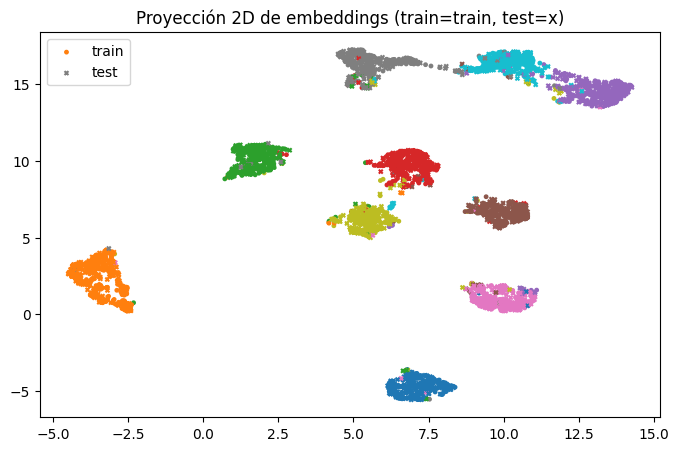

Linear probe acc: 0.9400 | k-NN acc: 0.9360


In [1]:
# Interfaz interactiva para experimentar arquitecturas, pérdidas y dimensiones latentes
# Pegar entero en una sola celda de Google Colab y ejecutar.

# ---------- Instalación (descomentar si hace falta) ----------
# !pip install -q ipywidgets umap-learn
# from google.colab import output
# output.enable_custom_widget_manager()

# ---------- Imports ----------
import os, math, random, time
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, clear_output
import ipywidgets as widgets

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset, Dataset
from torchvision import datasets, transforms

from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
try:
    import umap
except Exception:
    umap = None

# ---------- Device & seed ----------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if device.type == "cuda": torch.cuda.manual_seed_all(SEED)

# ---------- Data (MNIST) ----------
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])
train_ds = datasets.MNIST(root="data", train=True, download=True, transform=transform)
test_ds  = datasets.MNIST(root="data", train=False, download=True, transform=transform)

# Small helper dataset for triplets
def build_label_index(dataset):
    label_to_idx = {}
    for i in range(len(dataset)):
        _, y = dataset[i]
        label_to_idx.setdefault(int(y), []).append(i)
    return label_to_idx

# ---------- Model factories ----------
INPUT_DIM = 28*28

def make_linear_ae(latent_dim):
    class LinearAE(nn.Module):
        def __init__(self, input_dim=INPUT_DIM, latent_dim=latent_dim):
            super().__init__()
            self.encoder = nn.Linear(input_dim, latent_dim, bias=False)
            self.decoder = nn.Linear(latent_dim, input_dim, bias=False)
        def forward(self, x):
            x = x.view(x.size(0), -1)
            z = self.encoder(x)
            recon = self.decoder(z).view(x.size(0),1,28,28)
            return recon, z
    return LinearAE()

def make_mlp_ae(latent_dim):
    class MLP_AE(nn.Module):
        def __init__(self, input_dim=INPUT_DIM, latent_dim=latent_dim):
            super().__init__()
            self.encoder = nn.Sequential(
                nn.Linear(input_dim, 512), nn.ReLU(),
                nn.Linear(512,256), nn.ReLU(),
                nn.Linear(256, latent_dim)
            )
            self.decoder = nn.Sequential(
                nn.Linear(latent_dim, 256), nn.ReLU(),
                nn.Linear(256, 512), nn.ReLU(),
                nn.Linear(512, input_dim)
            )
        def forward(self, x):
            x = x.view(x.size(0), -1)
            z = self.encoder(x)
            recon = self.decoder(z).view(x.size(0),1,28,28)
            return recon, z
    return MLP_AE()

def make_cnn_ae(latent_dim):
    class CNN_AE(nn.Module):
        def __init__(self, latent_dim=latent_dim):
            super().__init__()
            # Encoder conv -> flatten -> linear (latent)
            self.enc_conv = nn.Sequential(
                nn.Conv2d(1,16,3,2,1), nn.ReLU(),  # 14x14
                nn.Conv2d(16,32,3,2,1), nn.ReLU(), # 7x7
            )
            self.fc_enc = nn.Linear(32*7*7, latent_dim)
            self.fc_dec = nn.Linear(latent_dim, 32*7*7)
            self.dec_conv = nn.Sequential(
                nn.ConvTranspose2d(32,16,4,2,1), nn.ReLU(),  # 14x14
                nn.ConvTranspose2d(16,1,4,2,1), # 28x28
            )
        def forward(self, x):
            h = self.enc_conv(x)
            h_flat = h.view(h.size(0), -1)
            z = self.fc_enc(h_flat)
            dec_flat = self.fc_dec(z)
            dec_feat = dec_flat.view(-1,32,7,7)
            recon = self.dec_conv(dec_feat)
            return recon, z
    return CNN_AE()

def make_encoder_only(latent_dim, arch='mlp'):
    # Encoder used for contrastive/triplet: outputs normalized embeddings
    if arch == 'mlp':
        class Enc(nn.Module):
            def __init__(self):
                super().__init__()
                self.net = nn.Sequential(
                    nn.Linear(INPUT_DIM,512), nn.ReLU(),
                    nn.Linear(512,256), nn.ReLU(),
                    nn.Linear(256, latent_dim)
                )
            def forward(self, x):
                x = x.view(x.size(0), -1)
                z = self.net(x)
                z = F.normalize(z, dim=1)
                return z
        return Enc()
    elif arch == 'cnn':
        class EncCNN(nn.Module):
            def __init__(self):
                super().__init__()
                self.conv = nn.Sequential(
                    nn.Conv2d(1,16,3,2,1), nn.ReLU(),
                    nn.Conv2d(16,32,3,2,1), nn.ReLU()
                )
                self.fc = nn.Linear(32*7*7, latent_dim)
            def forward(self, x):
                h = self.conv(x)
                h = h.view(h.size(0), -1)
                z = self.fc(h)
                z = F.normalize(z, dim=1)
                return z
        return EncCNN()
    else:
        return make_mlp_ae(latent_dim).encoder  # fallback

# ---------- Loss implementations ----------
# Reconstruction: MSE (pixel-wise). Optionally BCE if using [0,1] outputs.
recon_loss_fn = nn.MSELoss()

# NT-Xent contrastive loss (simple)
def nt_xent(z1, z2, temperature=0.5):
    # z1, z2: normalized embeddings (N,D)
    N = z1.size(0)
    z = torch.cat([z1, z2], dim=0)  # 2N x D
    sim = torch.matmul(z, z.T) / temperature
    mask = (~torch.eye(2*N, dtype=torch.bool, device=sim.device)).float()
    exp_sim = torch.exp(sim) * mask
    denom = exp_sim.sum(dim=1)
    positives = torch.exp((z1 * z2).sum(dim=1) / temperature)
    pos = torch.cat([positives, positives], dim=0)
    # indices for numerator correspond to pairs (i, i+N) etc. This simplified version uses pos as computed.
    loss = -torch.log(pos / denom)
    return loss.mean()

# Triplet loss
triplet_loss_fn = nn.TripletMarginLoss(margin=1.0, p=2)

# ---------- Augmentations for contrastive ----------
import torchvision.transforms.functional as TF
def random_shift(img, max_shift=3):
    sx = random.randint(-max_shift, max_shift)
    sy = random.randint(-max_shift, max_shift)
    return TF.affine(img, angle=0, translate=(sx,sy), scale=1.0, shear=0)
def add_noise(img, std=0.15):
    return (img + torch.randn_like(img)*std).clamp(-1.0, 1.0)
def augment_two(img):
    a = add_noise(random_shift(img))
    b = add_noise(random_shift(img))
    return a, b

# ---------- Evaluation helpers ----------
def get_embeddings(model, loader, max_samples=None, encoder_only=False):
    model.to(device).eval()
    zs, ys = [], []
    with torch.no_grad():
        for x, y in loader:
            x = x.to(device)
            if encoder_only:
                z = model(x)
            else:
                out = model(x)
                if isinstance(out, tuple):
                    _, z = out
                else:
                    z = out
            if isinstance(z, torch.Tensor):
                z = z.cpu().numpy()
            zs.append(z)
            ys.append(y.numpy())
            if max_samples and sum(len(a) for a in ys) >= max_samples:
                break
    zs = np.concatenate(zs, axis=0)[:max_samples]
    ys = np.concatenate(ys, axis=0)[:max_samples]
    return zs, ys

def linear_probe(emb_train, y_train, emb_test, y_test):
    clf = LogisticRegression(max_iter=2000)
    clf.fit(emb_train, y_train)
    return accuracy_score(y_test, clf.predict(emb_test))

def knn_eval(emb_train, y_train, emb_test, y_test, k=5):
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(emb_train, y_train)
    return accuracy_score(y_test, knn.predict(emb_test))

# ---------- UI widgets ----------
arch_dropdown = widgets.Dropdown(
    options=[('Linear AE','linear_ae'), ('MLP AE','mlp_ae'), ('CNN AE','cnn_ae'), ('Encoder-only (MLP)','enc_mlp'), ('Encoder-only (CNN)','enc_cnn')],
    value='mlp_ae', description='Arquitectura:'
)
loss_options = widgets.SelectMultiple(
    options=[('Recon MSE','recon'), ('NT-Xent (contrastive)','ntxent'), ('Triplet','triplet')],
    value=['recon'], description='Pérdidas:'
)
latent_slider = widgets.IntSlider(value=32, min=2, max=256, step=2, description='Latent dim:')
epochs_slider = widgets.IntSlider(value=6, min=1, max=40, step=1, description='Epochs:')
batch_slider = widgets.IntSlider(value=256, min=32, max=1024, step=32, description='Batch:')
lr_text = widgets.FloatText(value=1e-3, description='LR:')
subset_size = widgets.IntSlider(value=10000, min=2000, max=60000, step=1000, description='Train subset:')
temperature = widgets.FloatSlider(value=0.5, min=0.05, max=1.0, step=0.05, description='Temp:')
seed_text = widgets.IntText(value=SEED, description='Seed:')

train_button = widgets.Button(description='Entrenar', button_style='success')
stop_button = widgets.Button(description='Stop', button_style='danger')
vis_button = widgets.Button(description='Visualizar emb', button_style='info')
manip_button = widgets.Button(description='Abrir manipulador latente', button_style='primary')

log_out = widgets.Output(layout={'border': '1px solid black'})

# ---------- Training loop (single function that adapts to options) ----------
training_state = {"stop": False}

def train_model(b):
    # read UI parameters
    clear_output(wait=False)
    display(ui_top, ui_middle, ui_bottom, log_out)
    training_state["stop"] = False
    seed = int(seed_text.value)
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if device.type == 'cuda': torch.cuda.manual_seed_all(seed)
    arch = arch_dropdown.value
    latent_dim = int(latent_slider.value)
    losses_selected = list(loss_options.value)
    epochs = int(epochs_slider.value)
    batch = int(batch_slider.value)
    lr = float(lr_text.value)
    subset = int(subset_size.value)
    temp = float(temperature.value)

    # prepare dataset loaders
    train_loader_local = DataLoader(Subset(train_ds, list(range(subset))), batch_size=batch, shuffle=True)
    test_loader_local = DataLoader(test_ds, batch_size=batch, shuffle=False)

    # build model depending on architecture
    if arch == 'linear_ae':
        model = make_linear_ae(latent_dim)
        encoder_only = False
    elif arch == 'mlp_ae':
        model = make_mlp_ae(latent_dim)
        encoder_only = False
    elif arch == 'cnn_ae':
        model = make_cnn_ae(latent_dim)
        encoder_only = False
    elif arch == 'enc_mlp':
        model = make_encoder_only(latent_dim, arch='mlp')
        encoder_only = True
    elif arch == 'enc_cnn':
        model = make_encoder_only(latent_dim, arch='cnn')
        encoder_only = True
    else:
        model = make_mlp_ae(latent_dim)
        encoder_only = False

    model = model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    start_time = time.time()

    with log_out:
        print(f"Entrenando: arch={arch}, losses={losses_selected}, latent={latent_dim}, epochs={epochs}, batch={batch}, lr={lr}")
    # training loop
    for ep in range(1, epochs+1):
        if training_state["stop"]:
            with log_out:
                print("Entrenamiento detenido por usuario.")
            break
        model.train()
        epoch_loss = 0.0
        n_samples = 0
        for batch_x, batch_y in train_loader_local:
            batch_x = batch_x.to(device)
            bsz = batch_x.size(0)
            loss_total = 0.0

            # Reconstruction if requested and model supports decoder
            if 'recon' in losses_selected and not encoder_only:
                recon, z = model(batch_x)
                loss_recon = recon_loss_fn(recon, batch_x)
                loss_total += loss_recon

            # NT-Xent: need two augmentations + encoder-only or encoder from model
            if 'ntxent' in losses_selected:
                if encoder_only:
                    z1, z2 = [], []
                    # create augmentations on the fly (works for normalized inputs)
                    for i in range(batch_x.size(0)):
                        a,b = augment_two(batch_x[i])
                        z1.append(model(a.unsqueeze(0).to(device)))
                        z2.append(model(b.unsqueeze(0).to(device)))
                    z1 = torch.cat(z1, dim=0); z2 = torch.cat(z2, dim=0)
                else:
                    # get encoder: if model returns (recon, z) then extract encoder via forward; we approximate by calling and taking z
                    z1_list, z2_list = [], []
                    for i in range(batch_x.size(0)):
                        a,b = augment_two(batch_x[i])
                        _, za = model(a.unsqueeze(0).to(device))
                        _, zb = model(b.unsqueeze(0).to(device))
                        z1_list.append(za); z2_list.append(zb)
                    z1 = torch.cat(z1_list, dim=0); z2 = torch.cat(z2_list, dim=0)
                    # normalize
                    z1 = F.normalize(z1, dim=1); z2 = F.normalize(z2, dim=1)
                loss_con = nt_xent(z1, z2, temperature=temp)
                loss_total += loss_con

            # Triplet: requires mining or sampling triplets from labels
            if 'triplet' in losses_selected:
                # For simplicity, sample random positives/negatives within batch
                # Build indices by labels in the current batch
                labels = batch_y.numpy()
                label_to_idx = {}
                for idx, lab in enumerate(labels):
                    label_to_idx.setdefault(int(lab), []).append(idx)
                anchors, positives, negatives = [], [], []
                for idx in range(len(labels)):
                    a_lab = int(labels[idx])
                    pos_candidates = label_to_idx[a_lab]
                    neg_lab = random.choice([l for l in label_to_idx.keys() if l != a_lab])
                    neg_candidates = label_to_idx[neg_lab]
                    p = random.choice(pos_candidates)
                    n = random.choice(neg_candidates)
                    anchors.append(batch_x[idx].unsqueeze(0))
                    positives.append(batch_x[p].unsqueeze(0))
                    negatives.append(batch_x[n].unsqueeze(0))
                A = torch.cat(anchors).to(device)
                P = torch.cat(positives).to(device)
                N = torch.cat(negatives).to(device)
                # encode
                if encoder_only:
                    za = model(A); zp = model(P); zn = model(N)
                else:
                    _, za = model(A); _, zp = model(P); _, zn = model(N)
                loss_trip = triplet_loss_fn(za, zp, zn)
                loss_total += loss_trip

            # Backprop
            opt.zero_grad()
            loss_total.backward()
            opt.step()
            epoch_loss += float(loss_total.item()) * bsz
            n_samples += bsz

        t_elapsed = time.time() - start_time
        with log_out:
            print(f"Ep {ep}/{epochs} - Avg Loss: {epoch_loss/max(1,n_samples):.6f} - Time elapsed: {t_elapsed:.1f}s")
    with log_out:
        print("Entrenamiento finalizado. Guardando modelo en memoria (objeto 'trained_model').")
    # store trained model globally for visualization
    global trained_model, last_arch, last_encoder_only, last_train_loader, last_test_loader
    trained_model = model
    last_arch = arch
    last_encoder_only = encoder_only
    last_train_loader = train_loader_local
    last_test_loader = test_loader_local

# ---------- UI wiring ----------
train_button.on_click(train_model)
def stop_train(b):
    training_state["stop"] = True
stop_button.on_click(stop_train)

# ---------- Visualization (t-SNE / UMAP) ----------
def visualize_embeddings(b):
    clear_output(wait=False)
    display(ui_top, ui_middle, ui_bottom, log_out)
    if 'trained_model' not in globals():
        with log_out:
            print("No hay modelo entrenado. Entrena primero.")
        return
    model = trained_model
    encoder_only = last_encoder_only
    # get embeddings
    emb_train, y_train = get_embeddings(model, last_train_loader, max_samples=2000, encoder_only=encoder_only)
    emb_test,  y_test  = get_embeddings(model, last_test_loader, max_samples=2000, encoder_only=encoder_only)
    # choose 2D embedding method
    method = 'umap' if umap is not None else 'tsne'
    with log_out:
        print(f"Generando proyección 2D con {method}...")
    if umap is not None:
        reducer = umap.UMAP(n_components=2, random_state=SEED)
        pts = reducer.fit_transform(np.vstack([emb_train, emb_test]))
    else:
        tsne = TSNE(n_components=2, random_state=SEED, init='pca')
        pts = tsne.fit_transform(np.vstack([emb_train, emb_test]))
    n_train = emb_train.shape[0]
    plt.figure(figsize=(8,5))
    plt.scatter(pts[:n_train,0], pts[:n_train,1], c=y_train, cmap='tab10', s=6, label='train')
    plt.scatter(pts[n_train:,0], pts[n_train:,1], c=y_test, cmap='tab10', marker='x', s=8, label='test')
    plt.title('Proyección 2D de embeddings (train=train, test=x)')
    plt.legend(loc='best')
    plt.show()
    # Evaluate linear probe & kNN
    acc_lin = linear_probe(emb_train, y_train, emb_test, y_test)
    acc_knn = knn_eval(emb_train, y_train, emb_test, y_test, k=5)
    with log_out:
        print(f"Linear probe acc: {acc_lin:.4f} | k-NN acc: {acc_knn:.4f}")

vis_button.on_click(visualize_embeddings)

# ---------- Latent manipulator ----------
def open_manipulator(b):
    clear_output(wait=False)
    display(ui_top, ui_middle, ui_bottom, log_out)
    if 'trained_model' not in globals():
        with log_out:
            print("Entrena un modelo primero para abrir el manipulador latente.")
        return
    model = trained_model
    encoder_only = last_encoder_only
    # fetch a pool of test examples
    pool = list(range(len(test_ds)))
    # create index selector
    idx_slider = widgets.IntSlider(value=0, min=0, max=len(pool)-1, description='Idx test:')
    label_label = widgets.Label(value='Etiqueta: -')
    n_sliders = min(12, int(latent_slider.value))  # mostrar hasta 12 sliders por practicidad
    sliders = [widgets.FloatSlider(value=0.0, min=-4.0, max=4.0, step=0.05, description=f'z[{i}]') for i in range(n_sliders)]
    out_man = widgets.Output(layout={'border':'1px solid black'})

    def load_idx(idx):
        x, y = test_ds[idx]
        x_in = x.unsqueeze(0).to(device)
        with torch.no_grad():
            if encoder_only:
                z = model(x_in).cpu().numpy().reshape(-1)
                # need a decoder? If encoder-only, cannot reconstruct. We'll only show neighbors in embedding space.
                recon = None
            else:
                recon, z = model(x_in)
                z = z.cpu().numpy().reshape(-1)
                recon = recon.cpu().numpy().squeeze()
        # set sliders
        for i, s in enumerate(sliders):
            s.value = float(z[i]) if i < len(z) else 0.0
        label_label.value = f'Etiqueta: {int(y)}'
        # show original + recon if exists
        with out_man:
            clear_output(wait=True)
            plt.figure(figsize=(6,3))
            plt.subplot(1,2,1); plt.imshow(((x.cpu().numpy().squeeze()*0.3081)+0.1307).clip(0,1), cmap='gray'); plt.title('Original'); plt.axis('off')
            if recon is not None:
                plt.subplot(1,2,2); plt.imshow(((recon*0.3081)+0.1307).clip(0,1), cmap='gray'); plt.title('Recon'); plt.axis('off')
            else:
                plt.subplot(1,2,2); plt.text(0.1,0.5,'No hay decoder (encoder-only)','fontsize=12'); plt.axis('off')
            plt.show()

    def on_idx_change(change):
        load_idx(change['new'])

    idx_slider.observe(on_idx_change, names='value')
    # slider change -> update reconstruction in real time
    def on_slider_change(change):
        x, y = test_ds[idx_slider.value]
        x_in = x.unsqueeze(0).to(device)
        with torch.no_grad():
            if encoder_only:
                base_z = model(x_in).cpu().numpy().reshape(-1)
                z_mod = base_z.copy()
                for i,s in enumerate(sliders):
                    if i < len(z_mod): z_mod[i] = float(s.value)
                # show nearest neighbors in embedding space
                # compute embeddings of test subset (first 2000)
                emb_all, labels_all = get_embeddings(model, DataLoader(test_ds, batch_size=256), max_samples=2000, encoder_only=True)
                # compute cosine similarities
                from sklearn.metrics.pairwise import cosine_similarity
                sims = cosine_similarity(emb_all, z_mod.reshape(1,-1)).reshape(-1)
                topk = sims.argsort()[::-1][:6]
                with out_man:
                    clear_output(wait=True)
                    plt.figure(figsize=(10,3))
                    for i, idx in enumerate(topk):
                        im = ((test_ds[idx][0].numpy().squeeze()*0.3081)+0.1307).clip(0,1)
                        plt.subplot(1,6,i+1); plt.imshow(im, cmap='gray'); plt.title(str(test_ds[idx][1])); plt.axis('off')
                    plt.suptitle('Vecinos más cercanos al z modificado (encoder-only)')
                    plt.show()
            else:
                # have decoder: build modified z and decode
                _, z0 = model(x_in)
                z0 = z0.cpu().numpy().reshape(-1)
                z_mod = z0.copy()
                for i,s in enumerate(sliders):
                    if i < len(z_mod): z_mod[i] = float(s.value)
                # decode via decoder network
                with torch.no_grad():
                    zt = torch.tensor(z_mod, dtype=torch.float32, device=device).unsqueeze(0)
                    recon_flat = model.decoder(zt) if hasattr(model, 'decoder') else model.decode(zt)
                    recon_img = recon_flat.cpu().numpy().reshape(28,28)
                    recon_img = ((recon_img*0.3081)+0.1307).clip(0,1)
                with out_man:
                    clear_output(wait=True)
                    plt.figure(figsize=(6,3))
                    plt.subplot(1,2,1); plt.imshow(((x.cpu().numpy().squeeze()*0.3081)+0.1307).clip(0,1), cmap='gray'); plt.title('Original'); plt.axis('off')
                    plt.subplot(1,2,2); plt.imshow(recon_img, cmap='gray'); plt.title('Recon mod'); plt.axis('off')
                    plt.show()

    for s in sliders:
        s.observe(on_slider_change, names='value')

    # initialize
    load_idx(0)
    # layout
    left = widgets.VBox([idx_slider, label_label])
    right = widgets.VBox(sliders)
    display(widgets.HBox([left, right]))
    display(out_man)

manip_button.on_click(open_manipulator)

# ---------- Layout ----------
ui_top = widgets.HBox([arch_dropdown, loss_options, latent_slider])
ui_middle = widgets.HBox([epochs_slider, batch_slider, subset_size, lr_text, temperature])
ui_bottom = widgets.HBox([train_button, stop_button, vis_button, manip_button, seed_text])

display(ui_top, ui_middle, ui_bottom, log_out)

# ---------- Final note ----------
print("""
USO:
- Escoge Arquitectura y Pérdidas, ajusta latent dim y hyperparams.
- Pulsa "Entrenar" para que arranque el entrenamiento (ver logs en el recuadro).
- Tras entrenar, pulsa "Visualizar emb" para proyección 2D y evaluación (linear probe & k-NN).
- Pulsa "Abrir manipulador latente" para manipular z de ejemplos de test (mostrar reconstrucciones o vecinos).
RECOMENDACIONES para demo en clase:
- Usa pocos epochs (3-10) para demostración rápida; aumenta epochs si quieres resultados más finos.
- Para observar analogías reales (rey-hombre+mujer=reina) usa embeddings de texto (word2vec/GloVe/transformers) en otra sesión.
""")

1) Consideraciones arquitectónicas

a) Lineal vs. no lineal

Un autoencoder lineal es esencialmente equivalente a Principal Component Analysis (PCA): aprende un subespacio lineal que maximiza varianza.

Útil para compresión y análisis global de varianza, pero no captura estructuras no lineales ni relaciones semánticas complejas.

Los autoencoders no lineales (MLP o CNN en imágenes, Transformers en texto) pueden modelar variedades no lineales, lo que es crucial cuando la semántica vive en geometrías complejas del espacio de datos.

b) Tipos de capas

Capas densas (MLP): datos tabulares o embeddings ya vectoriales.

Convolucionales (CNN): imágenes; preservan estructura espacial y ayudan a que el latente capture factores semánticos visuales.

Transformers / encoders de lenguaje: texto; capturan dependencias de largo alcance y semántica contextual.

c) Funciones de activación

ReLU / GELU: prácticas estándar; facilitan optimización en redes profundas.

tanh / ELU: pueden dar latentes más suaves, útiles si se quiere interpolación semántica estable.

Salida del decoder lineal para reconstrucción continua (píxeles reales).

En aprendizaje contrastivo, normalizar L2 el embedding al final del encoder favorece métricas angulares (coseno), alineadas con “direcciones semánticas”.

d) Dimensionalidad del espacio latente

Trade-off compresión vs. expresividad:

Muy pequeño → colapsa semántica (poca separabilidad).

Muy grande → memoriza detalles sin estructurar relaciones.

En práctica, se elige por validación en tareas downstream (linear probe, k-NN). Para semántica: dimensiones suficientes para separar conceptos, pero no tantas como para evitar estructura.

e) Regularización y estructura del latente

Normalización L2, dropout en el encoder y restricciones de ortogonalidad ayudan a evitar soluciones degeneradas.

En modelos variacionales (p. ej., Variational Autoencoder), el término KL impone una geometría controlada; variantes como β-VAE fomentan disentanglement (factores latentes más interpretables).

2) Funciones de pérdida más allá de la reconstrucción

La reconstrucción (MSE o BCE) no garantiza que las distancias/direcciones del latente sean semánticas. Para estructurar el espacio:

a) Pérdidas contrastivas (InfoNCE / NT-Xent)

Acercan ejemplos “positivos” (mismas entidades con augmentaciones) y alejan “negativos”.

Estructuran el espacio para que la similitud angular refleje cercanía semántica.

Son la base de enfoques tipo SimCLR.

b) Triplet loss (margen)

Usa tríos (ancla, positivo, negativo) para imponer:

𝑑
(
𝑎
,
𝑝
)
+
margen
<
𝑑
(
𝑎
,
𝑛
)


Muy efectiva cuando se pueden minar negativos difíciles. Induce orden geométrico útil para recuperación y ranking semántico.

c) Pérdidas angulares / coseno

Hacen que la dirección del embedding importe más que la norma, alineándose con analogías vectoriales (sumas/restas semánticas en NLP).

d) Supervisión débil o supervisada contrastiva

Si hay etiquetas, la supervised contrastive loss agrupa clases semánticas sin forzar prototipos rígidos, produciendo latentes transferibles.

e) Combinaciones de pérdidas

Reconstrucción + contrastiva: conserva fidelidad a los datos mientras se impone estructura semántica.

Regularizadores geométricos: penalizar colapsos (uniformidad en la hiperesfera), center loss para compactar clases, o pérdidas de clustering (p. ej., DeepCluster) para inducir estructura global.

3) Evaluación de la “calidad semántica” del embedding

Linear probe: congelar embeddings y entrenar un clasificador lineal → mide separabilidad semántica.

k-NN / recuperación: vecinos cercanos deben compartir significado.

Transfer learning: rendimiento en tareas nuevas.

Aritmética vectorial (NLP): direcciones consistentes capturan relaciones (ejemplos clásicos en word embeddings como word2vec).

4) Conclusión práctica

Para generar embeddings semánticos útiles y transferibles:

Arquitectura: encoder suficientemente expresivo (no lineal, capas adecuadas al dominio), latente normalizado y de dimensión validada empíricamente.

Pérdidas: ir más allá de reconstrucción. Usar contrastivas, triplet o angulares (idealmente combinadas con reconstrucción o regularización).

Evaluación: medir con linear probe, k-NN y tareas downstream.

En resumen, la semántica no “emerge” solo de comprimir: se impone geométricamente mediante la arquitectura y, sobre todo, mediante funciones de pérdida que moldean explícitamente las distancias y direcciones del espacio latente.